# Validating cell-type annotaions
1. [Visualize QC statistics for single-tissue analyses](#section1)
2. [Visualize QC statistics for integrated analyses](#section2)
3. [Single-tissue analyses vs. Integrated analyses](#section3)
4. [Identify marker genes for each cell type](#section4)
5. [Validation with ATAC-seq data](#section5)

In [1]:
## Load package and the seurat object
library(Seurat)
library(data.table)
library(dplyr)
library(ggplot2)
library(plotly)
library(patchwork)
library(clusterProfiler)
library(org.Hs.eg.db)
library(enrichplot)
library(GOSemSim)
library(gridExtra)
library(slingshot)
source("../../code/make_plots.R")
options(repr.plot.width=14, repr.plot.height=10)

dataDIR <- "../../output/output_dir/remove_dup/"
pal_atac <- readRDS("~/projects/Lung_scMultiomics_paper/data/color_codes.RDS")
pal_rna <- pal_atac
names(pal_rna)[3:4] <- c("memCD4_T", "naiCD4_T")
pal_rna[3:4] = c("#208A42", "#bae4b3")
ct_order <- c(
  "Naive_B",
  "Memory_B",
  "NK",
  "CD8_T",
  "naiCD4_T",
  "memCD4_T",
  "Treg",
  "Other"
)

Attaching SeuratObject

Seurat v4 was just loaded with SeuratObject v5; disabling v5 assays and
validation routines, and ensuring assays work in strict v3/v4
compatibility mode


Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘plotly’


The following object is masked from ‘package:ggplot2’:

    last_plot


The following object is masked from ‘package:stats’:

    filter


The following object is masked from ‘package:graphics’:

    layout




clusterProfiler v4.6.2  For help: https://yulab-smu.top/biomedical-knowledge-mining-book/

If you use clusterProfiler in published research, please cite:
T Wu, E Hu, S Xu, M Chen, P Guo, Z Dai, T Feng, L Zhou, W Tang, L Zhan, X Fu, S Liu, X Bo, and G Yu. clusterProfiler 4.0: A universal enr

In [26]:
pal_atac

Other       Treg Th17/CD4_T      CD4_T      CD8_T         NK   Memory_B 
 "#D51F26"  "#272E6A"  "#208A42"  "#89288F"  "#F47D2B"  "#FEE500"  "#8A9FD1" 
   Naive_B  CD8/CD4_T 
 "#C06CAB"  "#D8A767"

In [25]:
pal_rna <- pal_atac
names(pal_rna)[3:4] <- c("memCD4_T", "naiCD4_T")
pal_rna[3:4] = c("#74c476", "#bae4b3")

In [37]:
pal_atac <- readRDS("~/projects/Lung_scMultiomics_paper/data/color_codes.RDS")
pal_rna <- pal_atac
names(pal_rna)[3:4] <- c("memCD4_T", "naiCD4_T")
pal_rna[3:4] = c("#208A42", "#bae4b3") # "#208A42", 

In [3]:
immune.combined<-readRDS(paste0(dataDIR, "lungs_spleens_integrated.RDS"))
immune.combined@active.assay<-"RNA"
immune.combined

# lungs <- readRDS(paste0(dataDIR, "lungs_integrated.RDS"))
# spleens <- readRDS(paste0(dataDIR, "spleens_integrated.RDS"))

Loading required package: Signac

Signac built for for SeuratObject v4 was just loaded with SeuratObject
v5; disabling v5 assays and validation routines, and ensuring assays
work in strict v3/v4 compatibility mode



An object of class Seurat 
321146 features across 45820 samples within 4 assays 
Active assay: RNA (36601 features, 0 variable features)
 2 layers present: counts, data
 3 other assays present: ATAC, integrated, peaks
 2 dimensional reductions calculated: pca, umap

<a id='section1'></a>
## 1. Visualize QC statistics for single-tissue analyses

In [ ]:
lung<-readRDS("AGG_lungs/all_lungs_integrated_multi.rds")

p1 <- VlnPlot(lung, features = c("nCount_ATAC"),#, "nCount_RNA","percent.mt"), ncol = 3,
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 
p2 <- VlnPlot(lung, features = c("nCount_RNA"), 
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 
p3 <- VlnPlot(lung, features = c("percent.mt"), 
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 

#ggsave(p1|p2|p3, filename = "aggr_lung_statistics.pdf", width = 10, height = 4)

In [4]:
spleen<-readRDS("AGG_spleens/all_spleens_integrated_multi.rds")

p1 <- VlnPlot(lung, features = c("nCount_ATAC"),#, "nCount_RNA","percent.mt"), ncol = 3,
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 
p2 <- VlnPlot(lung, features = c("nCount_RNA"), 
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 
p3 <- VlnPlot(lung, features = c("percent.mt"), 
  log = TRUE, pt.size = 0) + NoLegend() + 
    theme(axis.text.y = element_text(size = 15),
          axis.title.x = element_blank(),
          axis.text.x = element_blank()) 

#ggsave(p1|p2|p3, filename = "aggr_spleen_statistics.pdf", width = 10, height = 4)

<a id='section2'></a>
## 2. QC statistics for integrated analyses

In [ ]:
## UMAP visualization for integrated dataset colored by tissue, batch, cell type
p1 <- 
DimPlot(immune.combined, reduction = "pca", 
              group.by = "tissue.ident", 
              cols = platte, 
              #split.by = "tissue.ident", 
              label = FALSE, 
              repel = TRUE) +
    theme(legend.text = element_text(size = 18))
p2 <- 
DimPlot(immune.combined, reduction = "pca", 
              group.by = "batch", 
              cols = platte, 
              #split.by = "tissue.ident", 
              label = FALSE, 
              repel = TRUE) +
    theme(legend.text = element_text(size = 18))
p3 <- 
DimPlot(immune.combined, reduction = "pca", 
              group.by = "CellType", 
              cols = platte, 
              #split.by = "tissue.ident", 
              label = FALSE, 
              repel = TRUE) +
    theme(legend.text = element_text(size = 18))
p1 + p2 + p3

### Filtering out cluster 4 with high MT gene expression

In [ ]:
orig_labels <- fread("../../output/rna_metadata.txt")
head(orig_labels)

immune.combined$PriorClusters <- 
    orig_labels$`integrated_snn_res.0.5`[match(rownames(immune.combined@meta.data), orig_labels$X)]
table(immune.combined$PriorClusters)

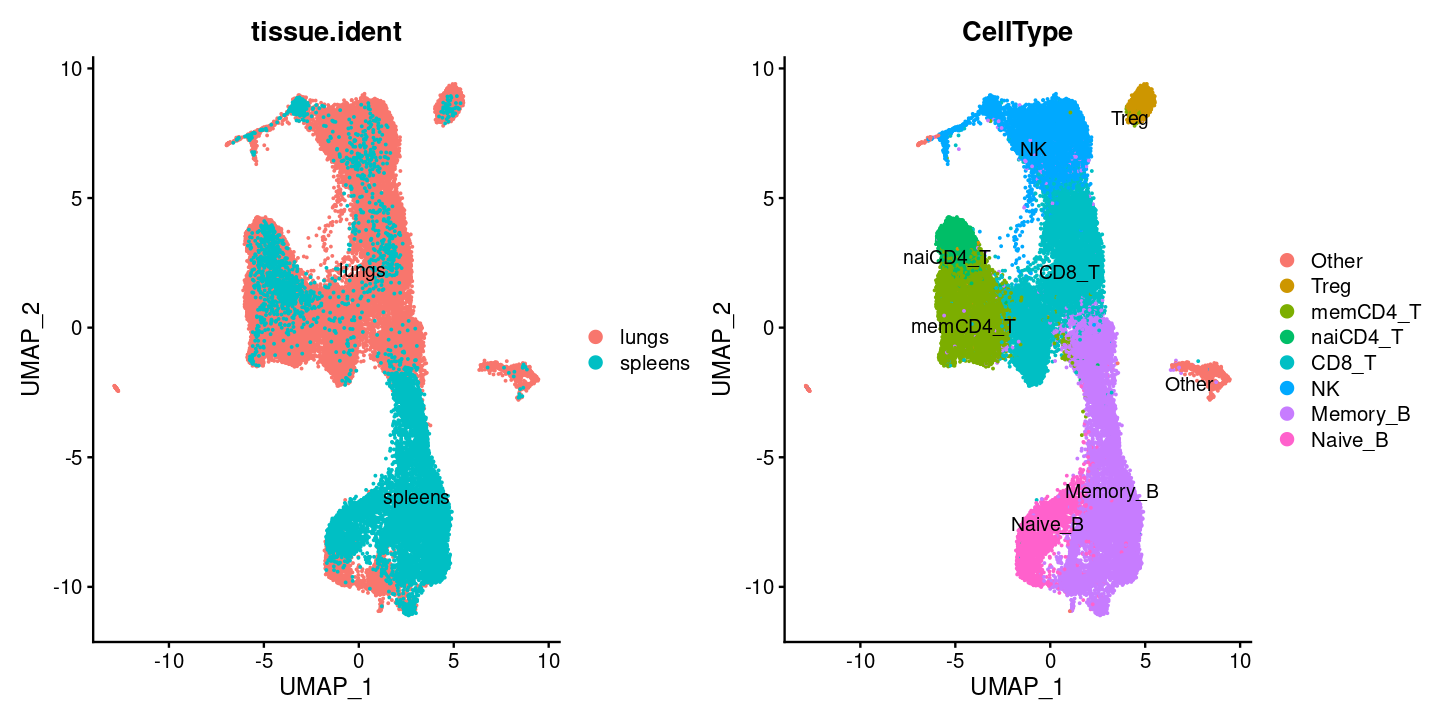

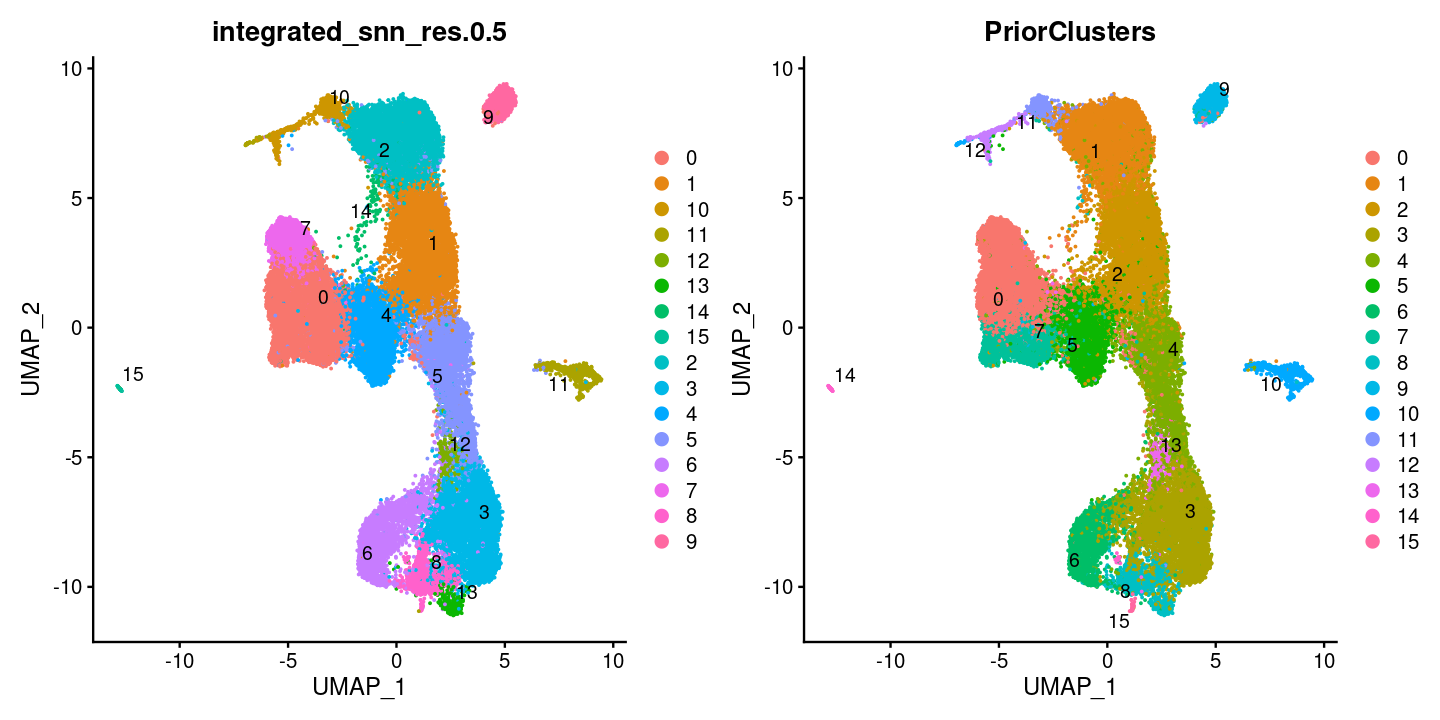

In [67]:
p1 <- DimPlot(immune.combined, reduction = "umap", group.by = "tissue.ident", label=TRUE, repel = TRUE)
p2 <- DimPlot(immune.combined, reduction = "umap", group.by = "integrated_snn_res.0.5", label = TRUE,
    repel = TRUE)
p3 <- DimPlot(immune.combined, reduction = "umap", group.by = "PriorClusters", label = TRUE,
    repel = TRUE)
p4 <- DimPlot(immune.combined, reduction = "umap", group.by = "CellType", label = TRUE,
    repel = TRUE)
p1 + p4
p2 + p3

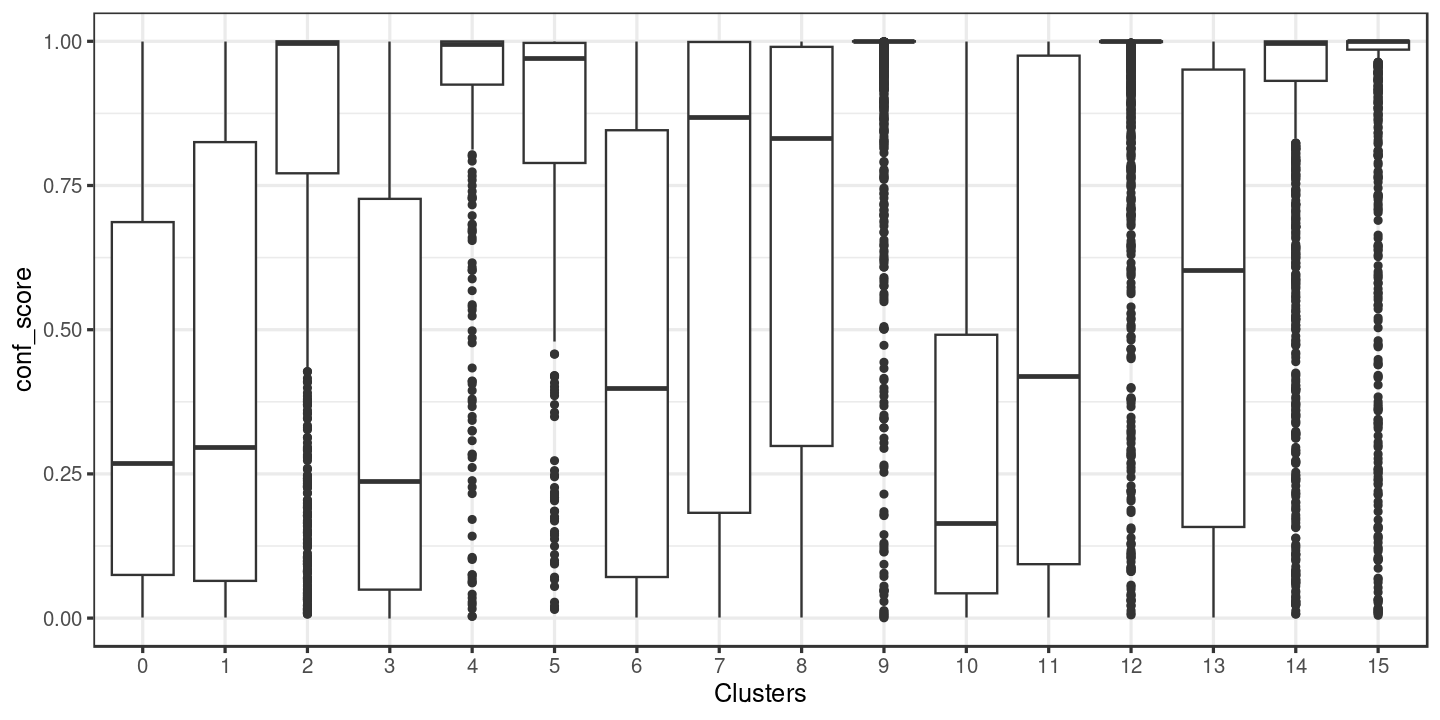

In [50]:
ggplot(labels, 
       aes(x = factor(over_clustering),
           y = conf_score)) + 
geom_boxplot() + xlab("Clusters") + 
theme_bw(base_size = 15)

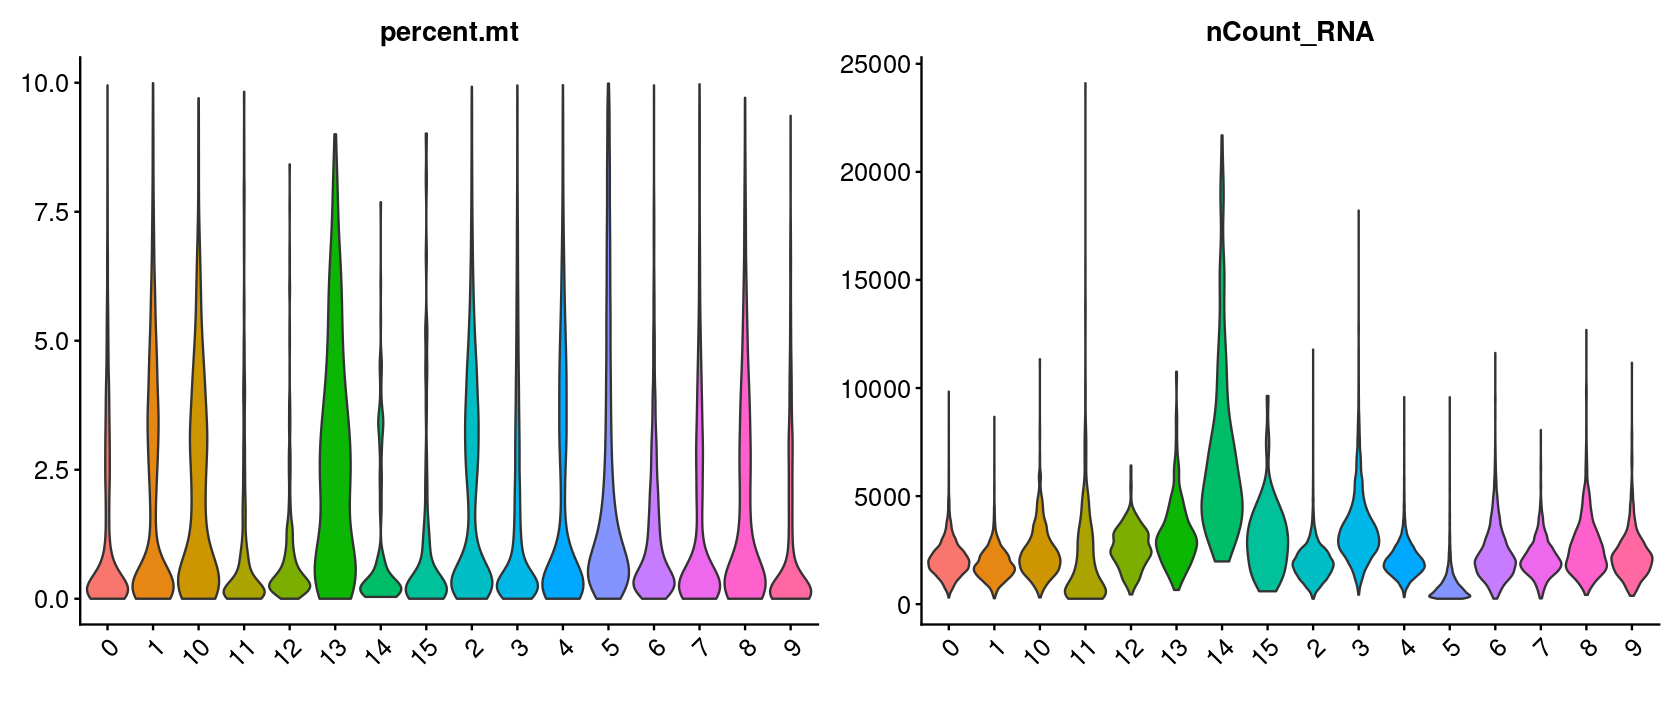

In [18]:
options(repr.plot.width=14, repr.plot.height=6)
p1 <-VlnPlot(immune.combined, features = c("percent.mt"), 
            #split.by = "tissue.ident",
            group.by = "integrated_snn_res.0.5", pt.size = 0) + 
    theme(axis.text.x = element_text(size = 15),
          axis.text.y = element_text(size = 15),
          legend.position = "none") + xlab("")

p2 <-VlnPlot(immune.combined, features = c("nCount_RNA"), 
            #split.by = "tissue.ident",
            group.by = "integrated_snn_res.0.5", pt.size = 0) + 
    theme(axis.text.x = element_text(size = 15),
          axis.text.y = element_text(size = 15),
          legend.position = "none") + xlab("")

p1|p2

In [10]:
immune.combined <- subset(immune.combined, PriorClusters != "4" | tissue.ident == "spleens")

In [11]:
immune.combined

An object of class Seurat 
321146 features across 42863 samples within 4 assays 
Active assay: RNA (36601 features, 0 variable features)
 2 layers present: counts, data
 3 other assays present: ATAC, integrated, peaks
 2 dimensional reductions calculated: pca, umap

In [12]:
saveRDS(immune.combined, "../../output/output_dir/remove_dup/lungs_spleens_integrated_sub.RDS")

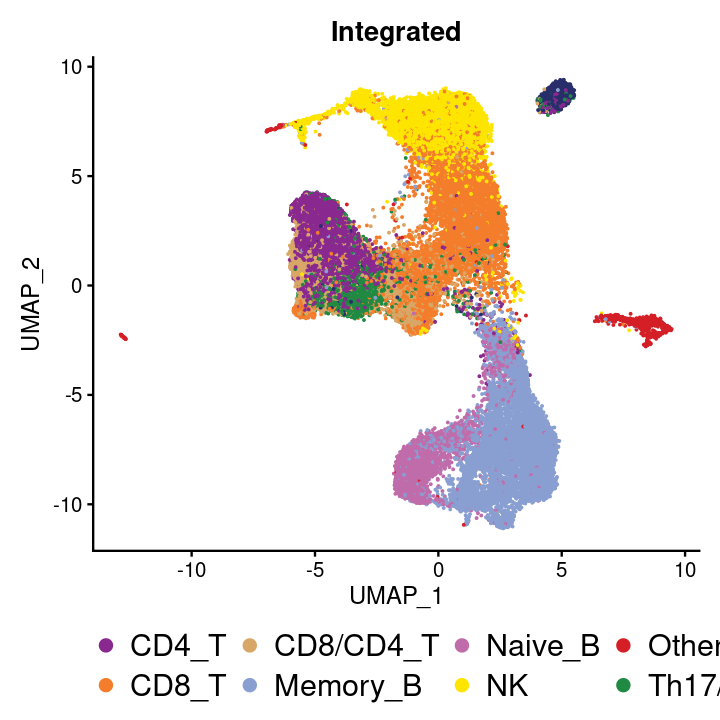

In [45]:
options(repr.plot.width=6, repr.plot.height=6)
p3 <- DimPlot(immune.combined, reduction = "umap", group.by = "PredCellType", 
              label.size = 5, label = FALSE, repel = TRUE, cols = pal_atac) + 
      ggtitle("Integrated") + theme(legend.position = "bottom", 
                                    legend.text = element_text(size = 18))
p3

<a id='section3'></a>

## 3. Single-tissue vs. Integrated analyses

In [3]:
lungs_labels <- fread("../../output/lungs_integrated_noDoublets.csv")
lungs@meta.data$majority_voting <- lungs_labels$majority_voting[match(rownames(lungs@meta.data), lungs_labels$V1)]
spleens_labels <- fread("../../output/spleens_integrated_noDoublets.csv")
spleens@meta.data$majority_voting <- spleens_labels$majority_voting[match(rownames(spleens@meta.data), spleens_labels$V1)]
labels <- fread("../../output/predicted_labels_integrated_removeDup.txt")

In [4]:
# Rename cell types for simplicity and consistency
lungs$SingleTissue <- 
    factor(lungs$majority_voting,
           labels = c("NK",
                      "NK",
                      "Other",
                      "Other",
                      "Memory_B",
                      "Naive_B",
                      "Other",
                      "Treg",
                      "naiCD4_T",
                      "memCD4_T",
                      "CD8_T"))
spleens$SingleTissue <- 
    factor(spleens$majority_voting,
           labels = c("NK",
                      "NK",
                      "Other",
                      "Memory_B",
                      "Naive_B",
                      "naiCD4_T",
                      "CD8_T"))

immune.combined$majority_voting <- labels$majority_voting
immune.combined$CellType <- immune.combined$majority_voting
immune.combined$CellType <-
    factor(immune.combined$CellType,
           levels = levels(factor(immune.combined$majority_voting)),
           label = c("Memory_B",
                         "NK",
                         "NK",
                         "Other",
                         "Other",
                         "Memory_B",
                         "Naive_B",
                         "Treg",
                         "naiCD4_T",
                         "memCD4_T",
                         "CD8_T"))

In [47]:
spleens@active.assay <- "RNA"

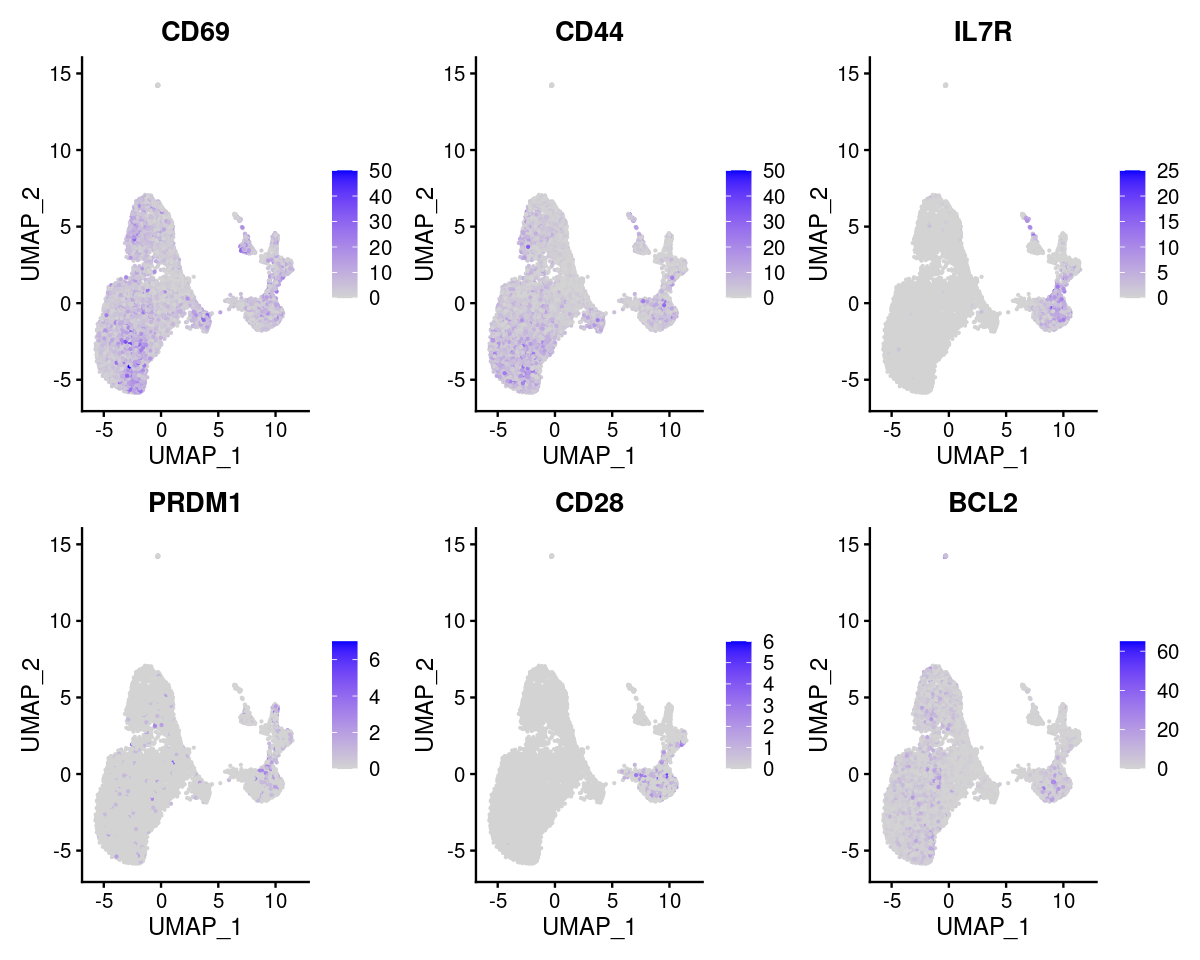

In [80]:
options(repr.plot.width=10, repr.plot.height=8)
FeaturePlot(spleens,slot = "counts",
            features = c("CD69", "CD44","IL7R",
                         "PRDM1", "CD28", "BCL2"),
            ncol = 3)

In [6]:
table(clusterDF$CellType)/sum(table(clusterDF$CellType))


 Memory_B        NK     Other   Naive_B      Treg  naiCD4_T  memCD4_T     CD8_T 
0.0000000 0.0000000 0.0000000 0.0000000 0.0000000 0.2314526 0.7685474 0.0000000 

In [5]:
cluster <- immune.combined@meta.data %>% filter(tissue.ident == "lungs" & grepl("CD4_T", CellType))
clusterDF <- data.frame(Barcode = rownames(cluster), CellType = cluster$CellType)

In [9]:
spleens@meta.data$Integrated <- immune.combined@meta.data$CellType[match(rownames(spleens@meta.data), rownames(immune.combined@meta.data))]

In [10]:
lungs@meta.data$Integrated <- immune.combined@meta.data$CellType[match(rownames(lungs@meta.data), rownames(immune.combined@meta.data))]

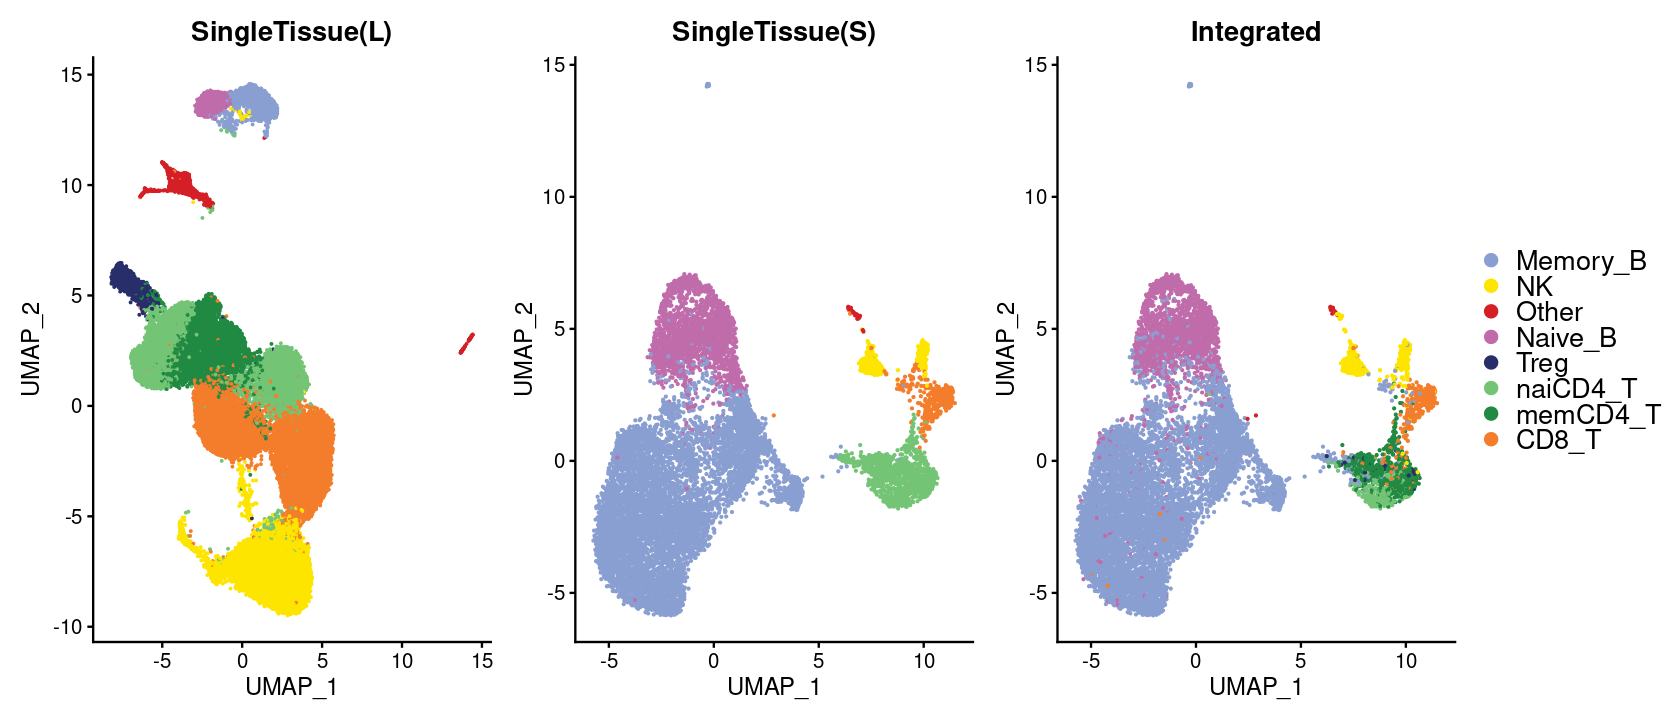

In [32]:
options(repr.plot.width=14, repr.plot.height=6)
p1 <- DimPlot(lungs, reduction = "umap", group.by = "SingleTissue", 
              cols = pal_rna, label.size = 5, label=FALSE, repel = TRUE) + ggtitle("SingleTissue(L)")
p2 <- DimPlot(spleens, reduction = "umap", group.by = "SingleTissue",
              label.size = 5, label=FALSE, cols = pal_rna) + ggtitle("SingleTissue(S)")
p3 <- DimPlot(spleens, reduction = "umap", group.by = "Integrated", 
              label.size = 5, label = FALSE, repel = TRUE, cols = pal_rna) + ggtitle("Integrated")
p <- (p1 + p2) & NoLegend()
p + (p3 + theme(legend.text = element_text(size = 16)))

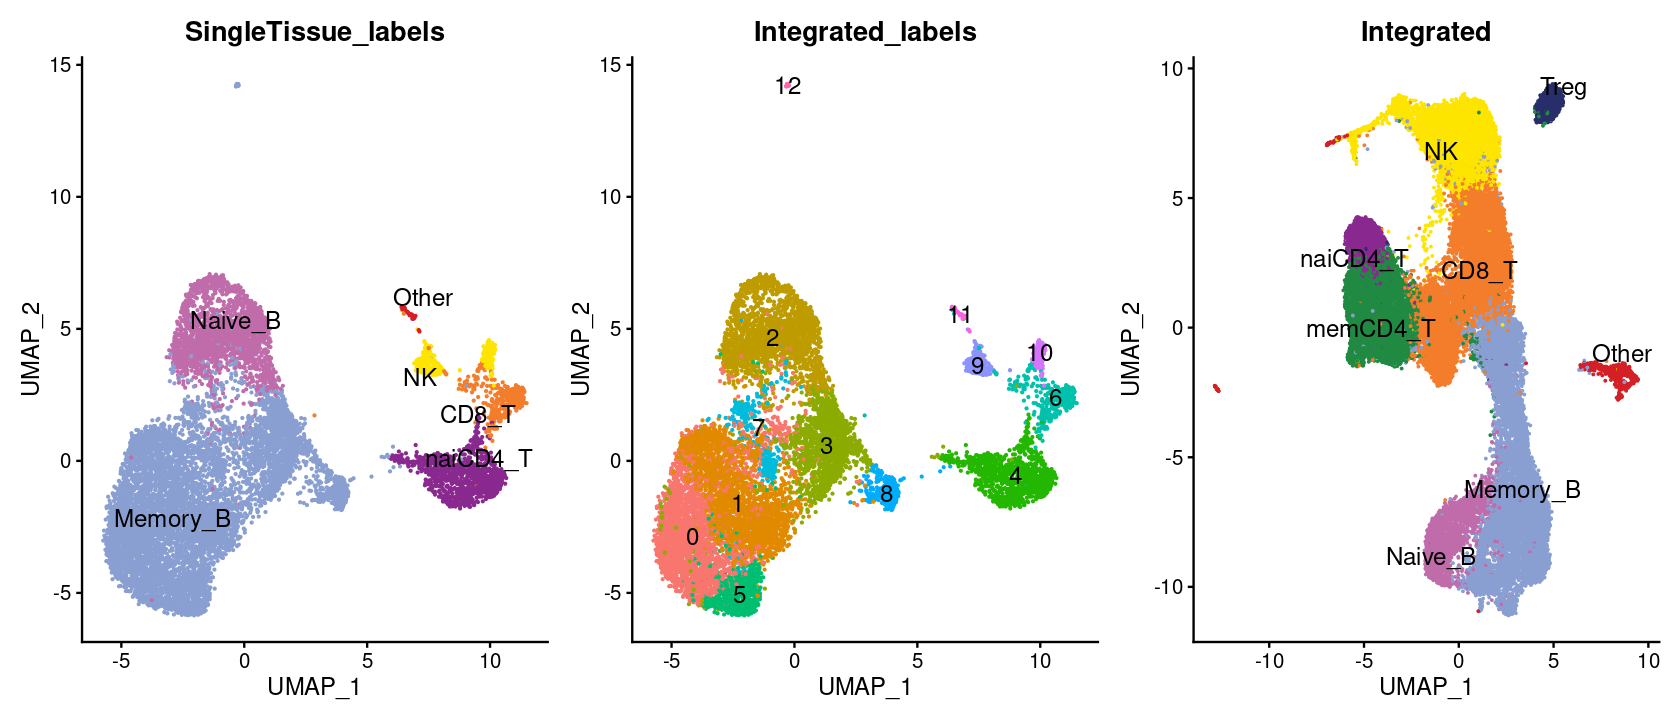

In [8]:
options(repr.plot.width=14, repr.plot.height=6)
p1 <- DimPlot(spleens, reduction = "umap", group.by = "SingleTissue", 
              cols = pal_rna, label.size = 5, label=TRUE, repel = TRUE) + ggtitle("SingleTissue_labels")
p2 <- DimPlot(spleens, reduction = "umap", group.by = "integrated_snn_res.0.5",
              label.size = 5, label=TRUE) + ggtitle("Integrated_labels")
p3 <- DimPlot(immune.combined, reduction = "umap", group.by = "CellType", 
              label.size = 5, label = TRUE, repel = TRUE, cols = pal_rna) + ggtitle("Integrated")
p1 + p2 + p3 & NoLegend() & theme(plot.title = element_text(hjust = 0.5))

In [5]:
jaccard <- function(a, b) {
    intersection = sum(a == b, na.rm = TRUE)
    union = length(a) + length(b) - intersection
    return (c(intersection, union, intersection/union))
}

labels_tbl <- rbind(
    data.frame(SingleTissue = lungs@meta.data$SingleTissue,
                         CellBarcode = rownames(lungs@meta.data)),
    data.frame(SingleTissue = spleens@meta.data$SingleTissue,
                         CellBarcode = rownames(spleens@meta.data)))
labels_tbl$Integrated <- immune.combined$CellType[match(labels_tbl$CellBarcode, 
                                                        rownames(immune.combined@meta.data))]

In [6]:
print("Overall similarity score:")
jaccard(labels_tbl$SingleTissue, labels_tbl$Integrated)


[1] "Overall similarity score:"


[1] 3.844400e+04 5.319600e+04 7.226859e-01

In [7]:
print("Similarity scores by cell type:")
similarity_tbl <-
t(sapply(unique(as.character(labels_tbl$SingleTissue)), function(i) {
    df <- labels_tbl %>% filter(SingleTissue == i)
    return(jaccard(df$SingleTissue, df$Integrated))
}))

[1] "Similarity scores by cell type:"


In [8]:
similarity_tbl <- data.frame(
    CellType = rownames(similarity_tbl),
    Score = similarity_tbl[, 3])
similarity_tbl

,CellType,Score
,<chr>,<dbl>
NK,NK,0.9334161
naiCD4_T,naiCD4_T,0.1606977
CD8_T,CD8_T,0.9043397
memCD4_T,memCD4_T,0.8577438
Naive_B,Naive_B,0.8519845
Treg,Treg,0.8889868
Memory_B,Memory_B,0.9215726
Other,Other,0.9100204


In [13]:
saveRDS(similarity_tbl, "../../data/plots/single_tissue_vs_integrated_labels")

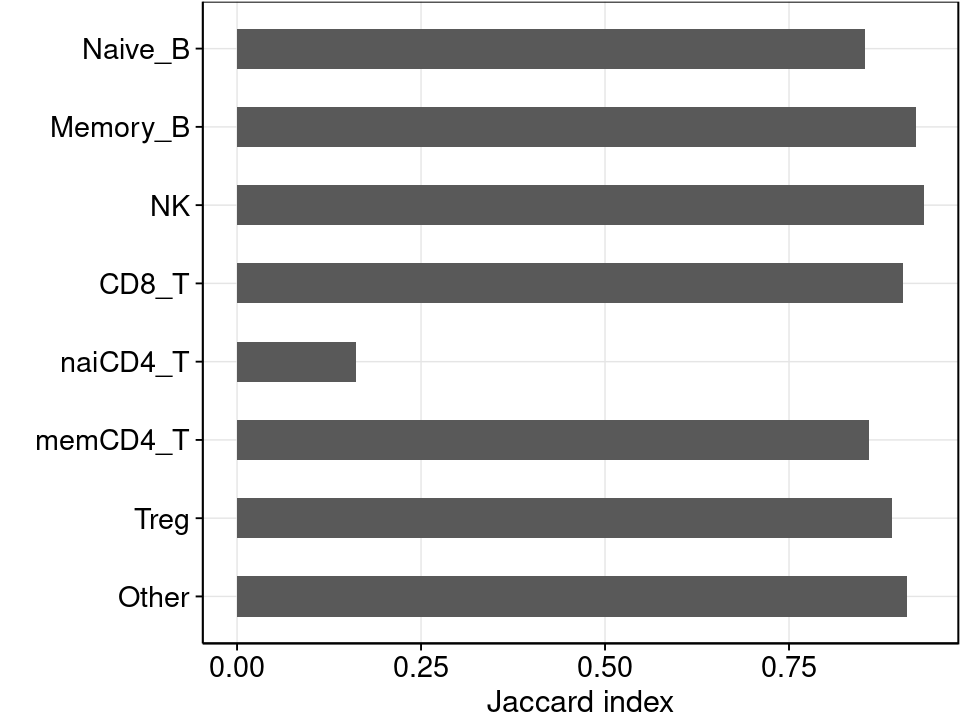

In [18]:
options(repr.plot.width=8, repr.plot.height=6)
ggplot(similarity_tbl %>% mutate(CellType = factor(CellType, levels = rev(ct_order))), 
       aes(y = CellType,
           x = Score)) + 
geom_col(width = 0.5) + 
theme_pub(base_size = 17) + 
ylab("") + xlab("Jaccard index")


In [74]:
idx <- which(labels_tbl$SingleTissue == "naiCD4_T" & labels_tbl$Integrated == "Memory_B")
filtered <- labels_tbl[setdiff(1:nrow(labels_tbl), idx), ] %>%
    filter(SingleTissue == "naiCD4_T")
table(filtered$Integrated)


Memory_B       NK    Other  Naive_B     Treg naiCD4_T memCD4_T    CD8_T 
       0       62        1        5       88     2082     2227      409 

In [42]:
orig_labels <- fread("../../output/rna_metadata.txt")
head(orig_labels)

immune.combined$PriorClusters <- 
    orig_labels$`integrated_snn_res.0.5`[match(rownames(immune.combined@meta.data), orig_labels$X)]
table(immune.combined$PriorClusters)

orig.ident,nCount_RNA,nFeature_RNA,percent.mt,nCount_ATAC,nFeature_ATAC,integrated_snn_res.0.5,seurat_clusters,immune_low,lung_atlas,⋯,ATAC.weight,wsnn_res.0.8,wsnn_res.0.5,wsnn_res.0.2,wsnn_MajorityVoting,core_ID,CellBarcode,X,SingleTissue,PredCellType
<int>,<int>,<int>,<dbl>,<int>,<int>,<int>,<int>,<chr>,<chr>,⋯,<dbl>,<int>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
2,4891,2351,1.819669,20272,8234,8,9,Memory B cells,B cells,⋯,0.4876775,14,14,9,Naive B cells,SMO-3,SMO-3#AAACAGCCAACAACAA,AAACAGCCAACAACAA-2_1,Memory B cells,Memory_B
2,2106,1225,4.415954,7866,3694,1,7,CD16+ NK cells,NK cells,⋯,0.6140445,3,5,7,CD16+ NK cells,SMO-3,SMO-3#AAACAGCCACAGCCTG,AAACAGCCACAGCCTG-2_1,CD16+ NK cells,NK
2,2503,1303,3.995206,8074,3733,0,2,Tcm/Naive helper T cells,CD4 T cells,⋯,0.5805850,11,11,2,Tem/Trm cytotoxic T cells,SMO-3,SMO-3#AAACAGCCAGGATGGC,AAACAGCCAGGATGGC-2_1,Tcm/Naive helper T cells,Th17/CD4_T
2,3573,1591,4.114190,19628,8126,0,2,Tcm/Naive helper T cells,CD4 T cells,⋯,0.5648134,11,11,2,Tem/Trm cytotoxic T cells,SMO-3,SMO-3#AAACAGCCATCAGTAT,AAACAGCCATCAGTAT-2_1,Tcm/Naive helper T cells,Th17/CD4_T
2,6324,2584,1.391524,856,451,2,7,Tem/Trm cytotoxic T cells,CD8 T cells,⋯,0.5266945,3,5,7,CD16+ NK cells,SMO-3,SMO-3#AAACAGCCATGAAGTA,AAACAGCCATGAAGTA-2_1,Tem/Trm cytotoxic T cells,CD8_T
2,3075,1388,4.715447,10015,4639,7,3,Type 17 helper T cells,CD4 T cells,⋯,0.4803607,8,9,3,Tem/Trm cytotoxic T cells,SMO-3,SMO-3#AAACAGCCATTAAACC,AAACAGCCATTAAACC-2_1,Type 17 helper T cells,CD8_T



   0    1    2    3    4    5    6    7    8    9   10   11   12   13   14   15 
6889 6680 6815 6117 4740 4311 2561 2476 1690 1165  813  686  426  325   90   36 

### Final UMAP plots for RNA-seq library

In [19]:
immune.combined <- readRDS("../../output/output_dir/remove_dup/lungs_spleens_integrated_sub.RDS")

In [4]:
pseubulk_list <- AggregateExpression(
  object = seurat_obj,
  assays = "RNA",
  slot = "counts",       # Use raw counts
  group.by = c("celltype", "sample_id"),
  return.seurat = FALSE  # Returns a list of matrices
)

# Extract the matrix for the RNA assay
counts_matrix <- pseubulk_list$RNA

# 2. Convert raw pseudobulk counts to CPM
cpm_matrix <- apply(counts_matrix, 2, function(x) {
  (x / sum(x)) * 1e6
})

# Verify CPM sums to 1 million per sample (column)
colSums(cpm_matrix)

Loading required package: Signac

Signac built for for SeuratObject v4 was just loaded with SeuratObject
v5; disabling v5 assays and validation routines, and ensuring assays
work in strict v3/v4 compatibility mode



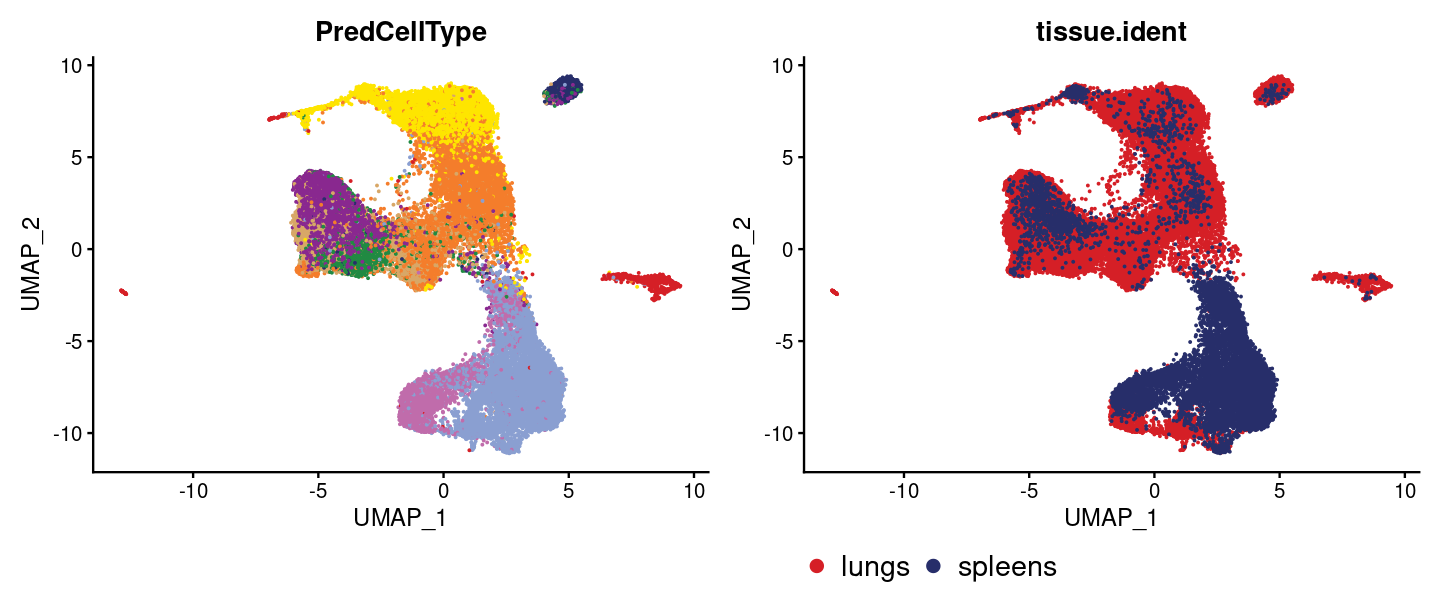

In [10]:
options(repr.plot.width=12, repr.plot.height=5)
p1 <- DimPlot(immune.combined, reduction = "umap", group.by = "PredCellType",
              label.size = 5, label=FALSE, cols = pal_atac) + theme(legend.position="none", legend.text = element_text(size = 17))
p2 <- DimPlot(immune.combined, reduction = "umap", group.by = "tissue.ident", 
              label.size = 5, label = FALSE, repel = TRUE, cols = c("#D51F26", "#272E6A"))+
                theme(legend.position="bottom", legend.text = element_text(size = 17))
p1 + p2 

<a id='section4'></a>

## 4 Identify marker genes for each cell type

In [4]:
immune.combined <- readRDS("../../output/output_dir/remove_dup/lungs_spleens_integrated_sub.RDS")

In [ ]:
pseubulk_list <- AggregateExpression(
  object = seurat_obj,
  assays = "RNA",
  slot = "counts",       # Use raw counts
  group.by = c("celltype", "sample_id"),
  return.seurat = FALSE  # Returns a list of matrices
)


In [4]:
immune.combined$grnCellType <- gsub("nai", "", gsub("mem", "", immune.combined$CellType))

Loading required package: Signac

Signac built for for SeuratObject v4 was just loaded with SeuratObject
v5; disabling v5 assays and validation routines, and ensuring assays
work in strict v3/v4 compatibility mode



In [7]:
Idents(immune.combined) <- immune.combined$grnCellType

In [11]:
marker_genes<- FindMarkers(subset(immune.combined, tissue.ident=="lungs"),
                           ident.1 =  "CD4_T", ident.2 = "Memory_B") 

In [14]:
saveRDS(marker_genes, "../../output/output_dir/remove_dup/dictys/lung_CD4_T_vs_Mem_B_DEG.RDS")

In [ ]:
immune.markers <- FindMarkers(immune.combined,
                              group.by = immune.combined$CellType,
                              only.pos = TRUE)

In [ ]:
## differential expression analysis across cell types with the Wilcoxon rank sum test

immune.markers <- FindAllMarkers(immune.combined,
                                 group.by = immune.combined$CellType,
                                 only.pos = TRUE)
immune.markers %>%
    group_by(cluster) %>%
    dplyr::filter(avg_log2FC > 1)

immune.markers %>%
    group_by(cluster) %>%
    dplyr::filter(p_val_adj < 0.001) %>%
    arrange(desc(avg_log2FC)) %>%
    slice_head(n = 5) %>%
    ungroup() -> top5

### Dotplots for the expression of known marker genes across immune cells

In [3]:
markerGenes <- c(
    "CD69","IGHD", 
    "IL4R", "MS4A1",
      "BANK1", 
      "GNLY", "NKG7",
      "CD8B", "ITGAE", "GZMK",
      "LEF1", "TCF7", "IL7R",
      "CD28", "PRDM1", "CCR7",
      "CTLA4", "IL2RA", "FOXP3")

In [6]:
immune.combined$CellType <- 
    factor(immune.combined$CellType, 
           levels = rev(ct_order))
Idents(immune.combined) <- immune.combined$CellType
p2 <-
    DotPlot(
        subset(immune.combined, subset= CellType != "Other"),
        features = markerGenes) + 
    RotatedAxis() + xlab("") + ylab("") 
   

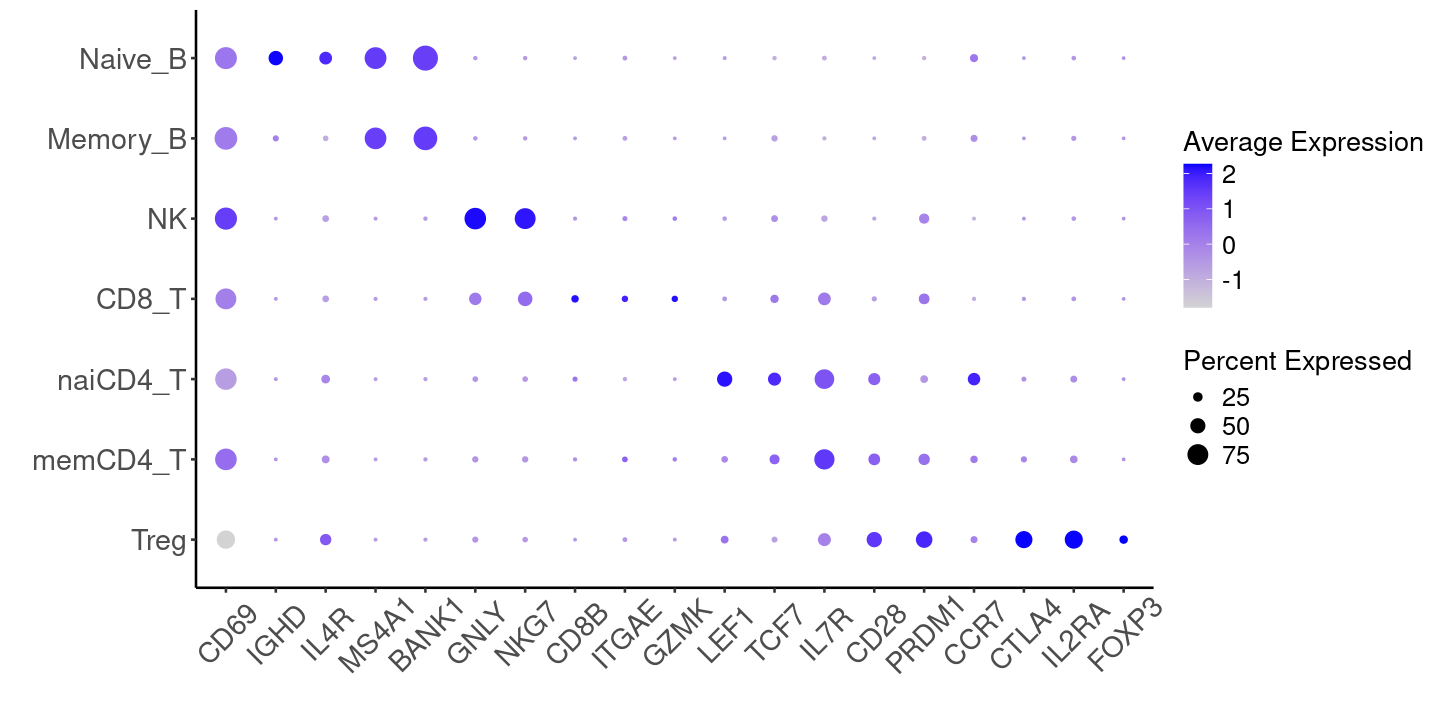

In [9]:
options(repr.plot.width=12, repr.plot.height= 6)
p2 + theme_classic(base_size = 12) + 
    theme(axis.text.x = element_text(size = 17, angle = 45, vjust=0.6),
          axis.text.y = element_text(size = 17),
          legend.title = element_text(size = 16),
          legend.text = element_text(size = 15))

### Dotplot split by tissue

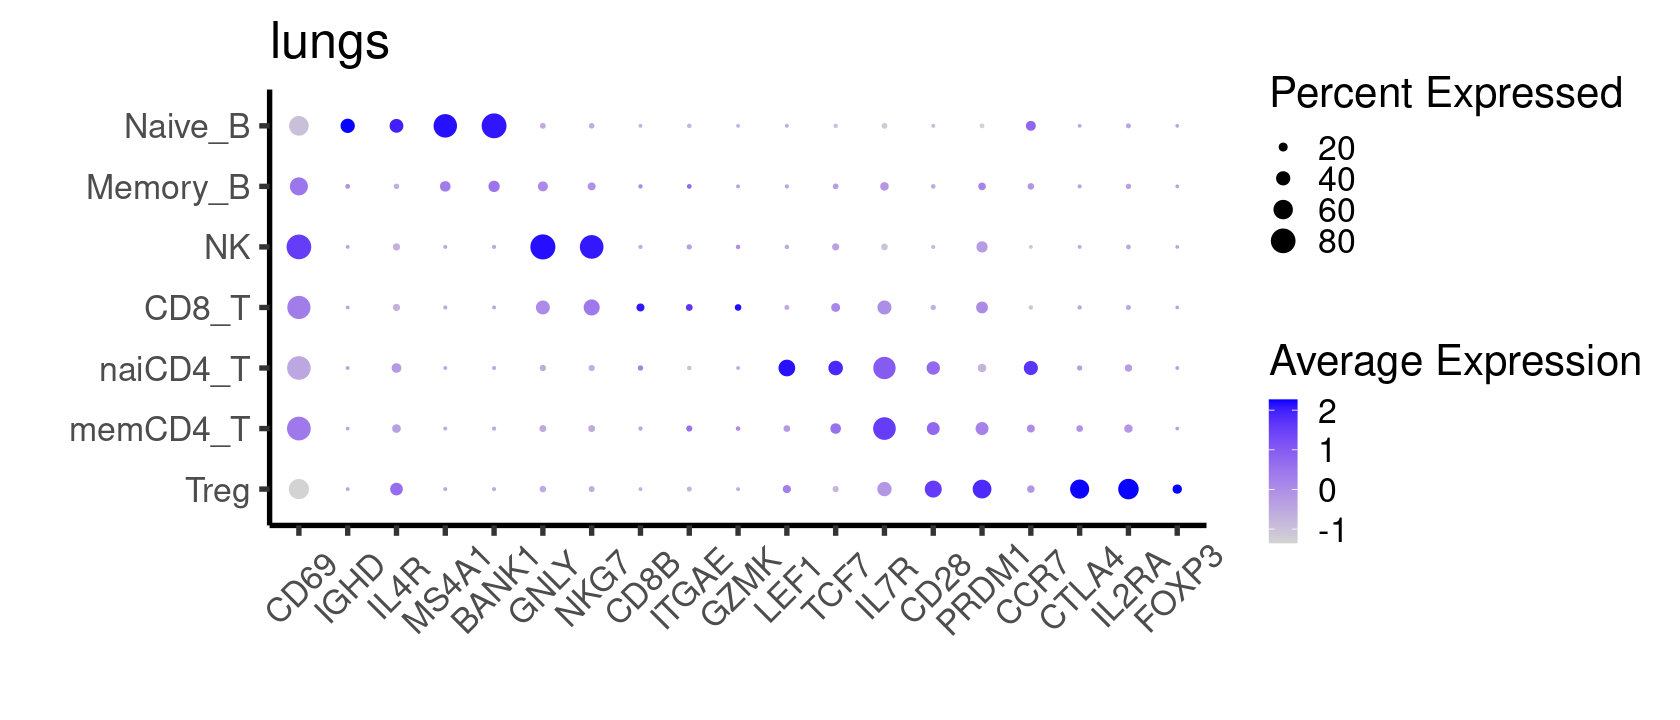

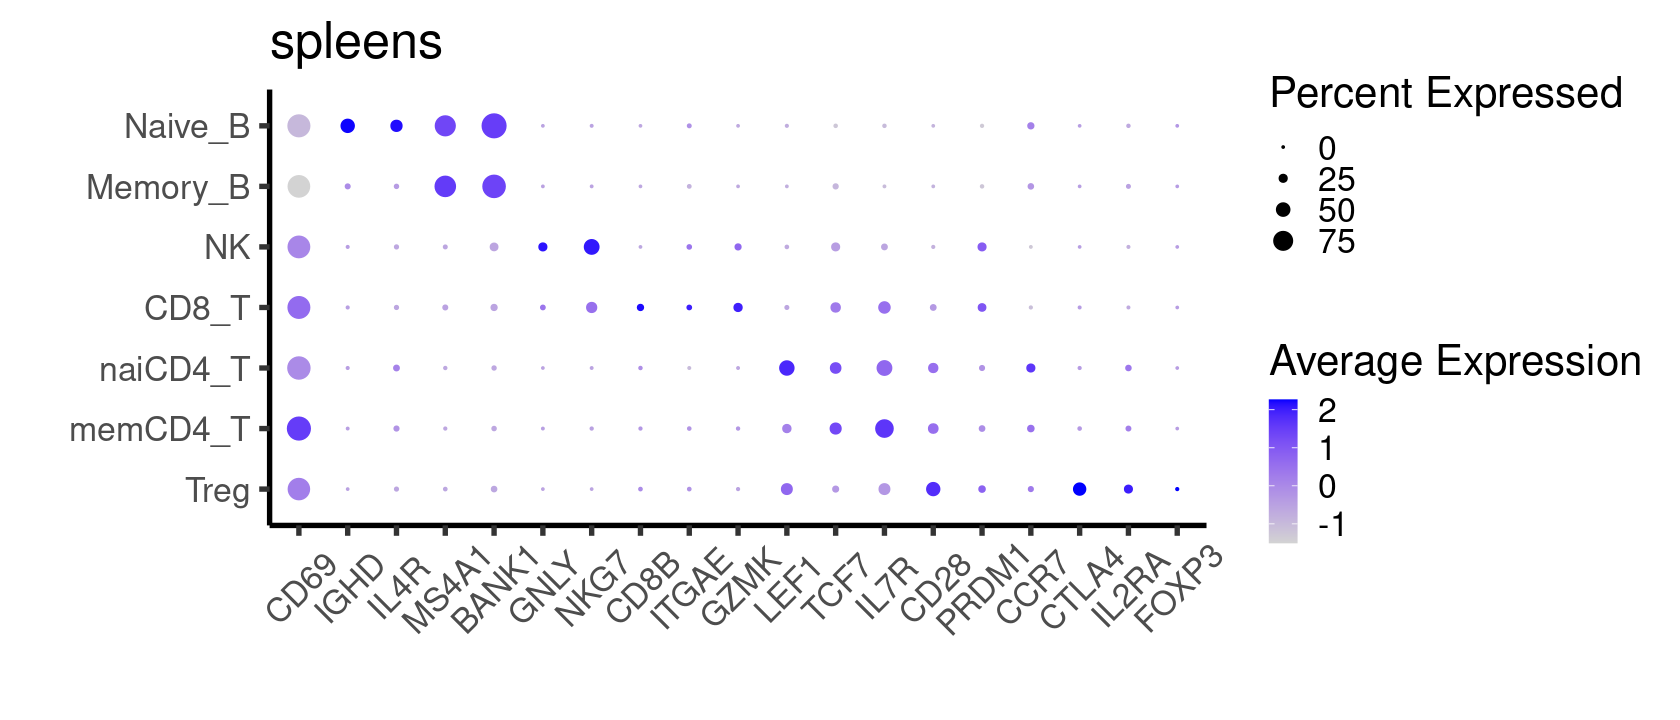

In [81]:
options(repr.plot.width=14, repr.plot.height= 6)
DotPlot(subset(immune.combined, CellType != "Other" & tissue.ident == "lungs"), 
        features = markerGenes) + 
        RotatedAxis() + xlab("") + ylab("") + 
theme_classic(base_size = 25) + 
theme(axis.text.x = element_text(angle = 45, vjust=0.6)) + ggtitle("lungs")

DotPlot(subset(immune.combined, CellType != "Other" & tissue.ident == "spleens"), 
        features = markerGenes) + 
        RotatedAxis() + xlab("") + ylab("") + 
theme_classic(base_size = 25) + 
theme(axis.text.x = element_text(angle = 45, vjust=0.6)) + ggtitle("spleens")

### Transferring to ATAC-seq labels 

In [46]:
atacmeta <- readRDS("../../output/atac_meta_updated.RDS")
colnames(atacmeta)

[1] "Sample"             "nMultiFrags"        "nMonoFrags"        
 [4] "nFrags"             "nDiFrags"           "TSSEnrichment"     
 [7] "ReadsInTSS"         "ReadsInPromoter"    "ReadsInBlacklist"  
[10] "PromoterRatio"      "PassQC"             "NucleosomeRatio"   
[13] "DoubletScore"       "DoubletEnrichment"  "BlacklistRatio"    
[16] "Clusters"           "predictedCell_Un"   "predictedGroup_Un" 
[19] "predictedScore_Un"  "CellType"           "majority_voting"   
[22] "Tissue"             "Status"             "Batch"             
[25] "Sex"                "Age"                "Race"              
[28] "CellGroup"          "ReadsInPeaks"       "FRIP"              
[31] "CellGroup2"         "CellGroup3"         "PredCellType"      
[34] "partial"            "LabelTransfer"      "MajorityVote"      
[37] "predictedCell2_Un"  "predictedGroup2_Un" "predictedScore2_Un"
[40] "CellBarcode"        "FilteredCellType"   "RNALabels"

In [47]:
rnameta <- immune.combined@meta.data
rnameta$core_ID <- factor(rnameta$full.ident, 
                          labels = c(paste0("SMO", "-", c(2,3,5,7,8,9)),
                                     paste0("SMO", "-", c(1, 4, 10))))
rnameta$CellBarcode <-paste(rnameta$core_ID, gsub("-", "_", rownames(rnameta)), sep = "#")
rnameta$CellBarcode <- unlist(lapply(rnameta$CellBarcode, function(i) {strsplit(i, "_")[[1]][1]}))
atacmeta <- 
  data.frame(atacmeta) %>%
    mutate(CellBarcode = unlist(lapply(rownames(atacmeta), function(i) {paste(strsplit(i, "-")[[1]][1:2], collapse = "-")})))
atacmeta$FilteredCellType <- rnameta$CellType[match(atacmeta$CellBarcode, rnameta$CellBarcode)] #seurat_clusters


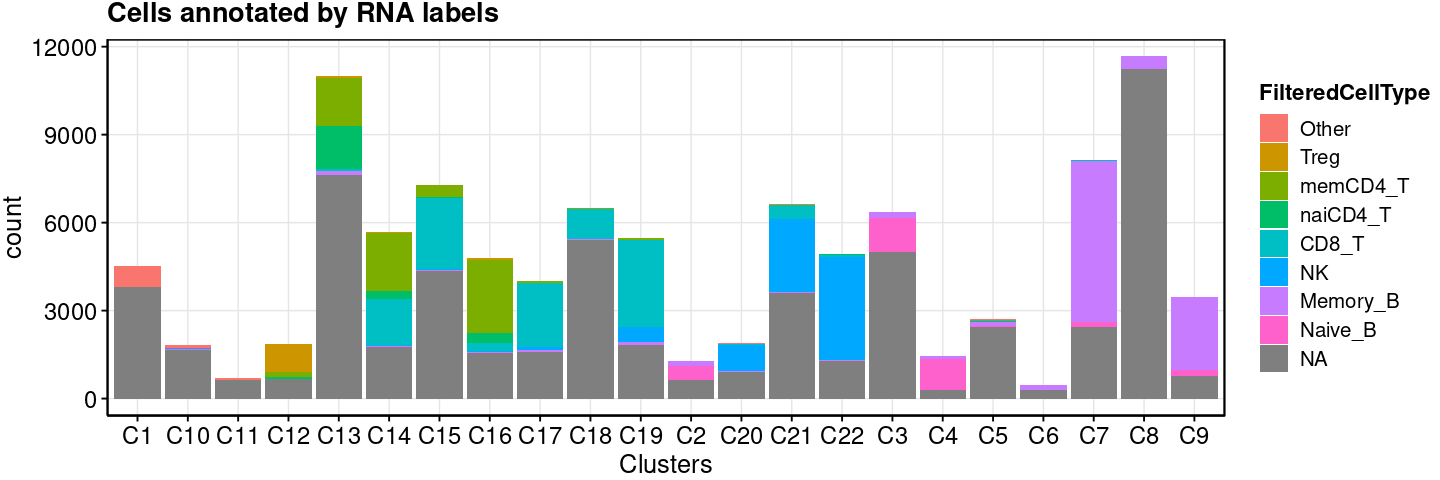

In [48]:
options(repr.plot.width=12, repr.plot.height= 4)
p4 <-   
ggplot(atacmeta,
       aes(x = Clusters,
           fill = FilteredCellType)) + 
  geom_bar() + 
  #theme_classic(base_size = 12) + 
  ggtitle("Cells annotated by RNA labels") + 
  theme_pub(base_size = 14)

p4

In [76]:
table(atacmeta$RNALabels)


 Memory_B     Other   Naive_B     CD8_T        NK     CD4_T      Treg  memCD4_T 
    26374      7011      9063     23195     13365     10969      1857      4776 
CD8/CD4_T 
     5667 

In [53]:
st_majority <- unlist(lapply(unique(atacmeta$Clusters), function(i) {
  ct <- atacmeta$FilteredCellType[atacmeta$Clusters == i]
  return(names(which.max(table(ct[!is.na(ct)]))))
}))

labels_tbl <-
    data.frame(Clusters = unique(atacmeta$Clusters),
           MajorityVoting = st_majority)

In [54]:
labels_tbl <-
    left_join(labels_tbl,
              unique(atacmeta[, c("Clusters", "PredCellType")]))
labels_tbl$RNALabels <- labels_tbl$PredCellType
labels_tbl$RNALabels[labels_tbl$Clusters == "C16"] <- "memCD4_T"

Joining with `by = join_by(Clusters)`


In [55]:
atacmeta$RNALabels <- atacmeta$Clusters
atacmeta$RNALabels <- 
    factor(atacmeta$Clusters, 
           levels = labels_tbl$Clusters,
           labels = labels_tbl$RNALabels)


<a id='section5'></a>

## 5 Cross-tissue DE analysis in each cell type 

We performed differential gene expression between tissue with pseudo-bulk samples using DESeq2 (v1.38.3) (Love, Huber, and Anders, 2014). The test was done on the RNA count matrix
aggregated by donor, tissue and cell types using Seurat::AggregateExpression. We also adjusted
for covariates including batch, ethnicity, age, and sex.

In [8]:
## Prepare aggregated RNA count matrix
sample_cov <- fread("../../data/sample_covariates.txt")
colnames(sample_cov)[3] <- "library_id"

# match by sample ID
metadata <- data.frame(
    library_id = c(paste("SMO", c(2,3,5,7,8,9), sep = "-"),
                   paste("SMO", c(1,4,10), sep = "-")),
    full.ident = c(paste("lungs", 1:6, sep = "_"),
                   paste("spleens", 1:3, sep = "_")))
metadata <- left_join(sample_cov[, 1:8], metadata, by = "library_id")
row_names <- rownames(immune.combined@meta.data)
immune.combined@meta.data <- left_join(immune.combined@meta.data, metadata)
rownames(immune.combined@meta.data) <- row_names

Joining with `by = join_by(full.ident)`


In [11]:
head(metadata)

ROBI,cells,library_id,submission_date,Age,Sex,Race,Asthmatic status,full.ident
<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>
554,Spleen,SMO-1,8092022,46,M,White: non specified,non,spleens_1
554,Lung,SMO-2,8092022,46,M,White: non specified,non,lungs_1
706,Lung,SMO-3,8092022,57,F,Black or African American,non,lungs_2
635,Spleen,SMO-4,10102022,57,F,White: non specified,non,spleens_2
635,Lung,SMO-5,10102022,57,F,White: non specified,non,lungs_3
597,Lung,SMO-7,10102022,30,M,Black or African American,non,lungs_4


In [9]:
cell_barcodes <- unlist(lapply(rownames(immune.combined@meta.data), function(i){strsplit(i, "_")[[1]][1]}))
cell_barcodes <- paste(immune.combined@meta.data$library_id, cell_barcodes, sep = "_")

rna_matrix <- immune.combined@assays$RNA@counts
colnames(rna_matrix) <- cell_barcodes

In [16]:
write.csv(as.matrix(rna_matrix), gzfile("/project/xinhe/jinggu/projects/u19_multiomics/peak2gene/scE2G/resources/u19_multiome/rna_count_matrix.csv.gz"),
         row.names = TRUE, quote = F)

Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 11.7 GiB”


In [25]:
colnames(immune.combined@meta.data)

[1] "orig.ident"             "nCount_RNA"             "nFeature_RNA"          
 [4] "percent.mt"             "nCount_ATAC"            "nFeature_ATAC"         
 [7] "integrated_snn_res.0.5" "seurat_clusters"        "immune_low"            
[10] "lung_atlas"             "tissue.ident"           "full.ident"            
[13] "nCount_peaks"           "nFeature_peaks"         "majority_voting"       
[16] "merged"                 "scDblFinder.class"      "PredCellType"          
[19] "CellType"               "PriorClusters"          "ROBI"                  
[22] "cells"                  "library_id"             "submission_date"       
[25] "Age"                    "Sex"                    "Race"                  
[28] "Asthmatic status"

In [16]:
## Group cells into pseudobulk by donor, tissue and cell types
pseudo_rna <- AggregateExpression(immune.combined, return.seurat = T, 
                                  assays = "RNA", slot = "counts",
                                  group.by = c("library_id", "PredCellType"))

row_names <- rownames(pseudo_rna@meta.data)
pseudo_rna@meta.data <- 
    left_join(pseudo_rna@meta.data %>%
               mutate(rowNames = row_names), 
              immune.combined@meta.data %>% 
                  mutate(rowNames = paste(library_id, PredCellType, sep = "_")) %>%
                  dplyr::select(rowNames, full.ident, PredCellType, library_id, ROBI, cells, submission_date, Age, Sex, Race,`Asthmatic status`) %>%
                  distinct()
              )

# Add rownames to metadata is necessary for seurat function to work.
rownames(pseudo_rna@meta.data) <- row_names
#colnames(pseudo_rna@meta.data)[11] <-"Asthmatic_status"

Centering and scaling data matrix

Joining with `by = join_by(rowNames)`


In [32]:
pseudo_lungs <- subset(pseudo_rna, full.ident %in% paste0("lungs_", 1:6))

In [33]:
saveRDS(pseudo_lungs@assays$RNA@counts, "~/cluster/projects/u19_multiomics/analyses/remove_dup/pseudobulk_RNA_counts_E2G.RDS")

In [76]:
## Perform cross-tissue DE analysis one cell type at a time with DESeq2

library(DESeq2)
DEG_list <-
    lapply(unique(pseudo_rna@meta.data$MainCellType), function(i) {
        sub_rna = subset(pseudo_rna, MainCellType == i)
        dds <- DESeqDataSetFromMatrix(countData = sub_rna@assays$RNA@counts, 
                                  colData = sub_rna@meta.data,
                                  design = ~ factor(submission_date) + Race + Age + Sex + cells) #Age as numeric
        dds <- DESeq(dds, betaPrior = FALSE)
        mm <- model.matrix(design(dds), colData(dds))
        qr(mm)$rank
        ncol(mm)
        print(qr(mm)$rank == ncol(mm))
        res <- results(dds, contrast = c("cells", "Lung", "Spleen"))
        return(res)
        })

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function

  the design formula contains one or more numeric variables that have mean or
  standard deviation larger than 5 (an arbitrary threshold to trigger this message).
  Including numeric variables with large mean can induce collinearity with the intercept.
  Users should center and scale numeric variables in the design to improve GLM convergence.

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are s

[1] TRUE


converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function

  the design formula contains one or more numeric variables that have mean or
  standard deviation larger than 5 (an arbitrary threshold to trigger this message).
  Including numeric variables with large mean can induce collinearity with the intercept.
  Users should center and scale numeric variables in the design to improve GLM convergence.

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are s

[1] TRUE


converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function

  the design formula contains one or more numeric variables that have mean or
  standard deviation larger than 5 (an arbitrary threshold to trigger this message).
  Including numeric variables with large mean can induce collinearity with the intercept.
  Users should center and scale numeric variables in the design to improve GLM convergence.

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are s

...

[1] TRUE


converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function

  the design formula contains one or more numeric variables that have mean or
  standard deviation larger than 5 (an arbitrary threshold to trigger this message).
  Including numeric variables with large mean can induce collinearity with the intercept.
  Users should center and scale numeric variables in the design to improve GLM convergence.

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are s

[1] TRUE


converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function

  the design formula contains one or more numeric variables that have mean or
  standard deviation larger than 5 (an arbitrary threshold to trigger this message).
  Including numeric variables with large mean can induce collinearity with the intercept.
  Users should center and scale numeric variables in the design to improve GLM convergence.

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are s

[1] TRUE


In [28]:
immune.combined <- readRDS("../../output/output_dir/remove_dup/lungs_spleens_integrated_sub.RDS")

In [5]:
immune.combined$MainCellType <- 
    factor(immune.combined$CellType,
           labels = c("Other",
                      "Treg",
                      "CD4_T",
                      "CD4_T",
                      "CD8_T",
                      "NK",
                      "Memory_B",
                      "Naive_B"))

In [78]:
names(DEG_list) <- unique(pseudo_rna@meta.data$MainCellType)
DEG_list <- lapply(names(DEG_list), function(i) {
  data.frame(DEG_list[[i]], cluster = gsub("-", "_", i)) %>%
    mutate(gene = rownames(DEG_list[[i]])) %>%
    filter(!is.na(log2FoldChange))
})

DEG_tbl <- do.call(rbind, DEG_list)

In [81]:
DEG_tbl <- do.call(rbind, DEG_list)
DEG_tbl %>% filter(gene == "GNLY")

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
GNLY,12.648198,2.972263,1.6225161,1.831885,6.696855e-02,3.850691e-01,Other,GNLY
GNLY1,6.912048,2.335298,1.4012816,1.666545,9.560501e-02,3.396096e-01,Treg,GNLY
GNLY2,99.596412,3.096007,1.1867872,2.608730,9.087894e-03,1.183829e-01,CD4_T,GNLY
GNLY3,703.314731,2.215558,1.1537303,1.920343,5.481458e-02,3.279205e-01,CD8_T,GNLY
GNLY4,1599.098355,1.875657,0.6155734,3.047007,2.311320e-03,4.895168e-02,NK,GNLY
GNLY5,162.494737,6.327376,1.3000249,4.867119,1.132367e-06,1.237137e-04,Memory_B,GNLY
GNLY6,32.300481,7.214666,1.2406112,5.815413,6.048451e-09,2.793661e-06,Naive_B,GNLY


In [57]:
names(DEG_list) <- unique(pseudo_rna@meta.data$MainCellType)
saveRDS(DEG_list, "../../output/output_dir/remove_dup/cross-tissue_DE/bulk_cross-tissue_DESeq2.RDS")

In [60]:
saveRDS(pseudo_rna@assays$RNA@counts, "../../output/output_dir/remove_dup/pseudobulk_RNA_counts.RDS")

In [6]:
ct_order <- c("Naive_B", "Memory_B", 'NK','CD8_T','CD4_T','Treg', 'Other')

In [97]:
#pseudo_rna$MainCellType <- factor(pseudo_rna$MainCellType, ct_order)
VlnPlot(subset(immune.combined, MainCellType != 'Other'), slot = "data", features = 'GNLY', group.by = "MainCellType", split.by = 'cells')

ERROR: [1m[33mError[39m in `as.Graph()`:[22m
[33m![39m Please provide rownames to the matrix before converting to a Graph


In [201]:
## Summarize number of DE genes into a table
DEG_counts <-
    lapply(DEG_list, function(i) {
        data.frame(i) %>% filter(padj <= 0.05) %>% 
            mutate(
                Category = 
                case_when(log2FoldChange > 0.58 ~ "lung-up",
                          log2FoldChange < -0.58 ~ "spleen-up")) %>%
            group_by(Category) %>% dplyr::summarise(n = n())
    })

In [202]:
do.call(rbind, DEG_counts) %>% filter(!is.na(Category)) %>% 
    mutate(CellType = unlist(lapply(names(DEG_list), function(i){rep(i, 2)})))

Category,n,CellType
<chr>,<int>,<chr>
lung-up,35,Other
spleen-up,3,Other
lung-up,60,Treg
spleen-up,9,Treg
lung-up,226,CD4_T
spleen-up,102,CD4_T
lung-up,100,CD8_T
spleen-up,70,CD8_T
lung-up,63,NK


### Visualize DE results with volcano plots

In [ ]:
## Load cross-tissue DE list
#DEG_list <- readRDS("output/u19_multiomics/output/u19_rna/bulk_cross-tissue_DESeq2.RDS")
DEG_list <- lapply(names(DEG_list), function(i) {
  data.frame(DEG_list[[i]], cluster = gsub("-", "_", i)) %>%
    filter(!is.na(log2FoldChange))
})

## Make a table of DE genes grouped by effect direction 
DGE_tbl <- do.call(rbind, DEG_list)

gginput <-
    DGE_tbl %>% 
      mutate(avg_log2FC = log2FoldChange) %>%
      filter(cluster != "Other" & padj <= 0.05) %>%
      mutate(group = case_when(avg_log2FC >= 1~ "Lung Up-regulated", 
                                 avg_log2FC <= -1 ~ "Spleen Up-regulated")) 
## Summarize total number of DE genes
totalCounts <- gginput %>% group_by(cluster) %>% dplyr::summarise(n = n())

In [ ]:
## Make a combined volcano plot for DE genes in each cell type
library(ggrepel)
selected <- ct_order[1:5]
gginput <- left_join(totalCounts, gginput, by = "cluster")
gginput$label <- sprintf("%s (%s)", gginput$cluster, gginput$n)
panel_order <-
  unlist(lapply(ct_order[1:5], function(i){levels(factor(gginput$label))[grep(i, levels(factor(gginput$label)))]}))
p1 <-
ggplot(
  gginput %>% filter(cluster %in% selected),
  aes(
    x = avg_log2FC ,
    y = -log10(pvalue),
    color = cluster,
  )
) +
  geom_point(size = 0.5) +
  scale_color_manual(values = c(pal_rna)) + 
  geom_point(
    data =
      gginput %>% 
      filter(padj > 0.05) %>%
      filter(cluster %in% selected),
    aes(x = avg_log2FC, y = -log10(pvalue)),
    color = alpha("grey", 0.7),
    size = 0.5
  ) +
  geom_text_repel(
    data = gginput %>% filter(cluster %in% selected),
    aes(label = ifelse(abs(avg_log2FC) >= 0.58, gene, "")),
    color = "grey30",
    #max.overlaps = 15,
    nudge_x = 0.1, nudge_y = 0.1,
    size = 2) +
  facet_wrap(~ factor(label, levels = panel_order), nrow = 2) +
  theme_pub() + 
  ylab("-log10(p-value)") + #xlim(c(-5, 10)) + 
  theme(legend.position = "none")

In [9]:
table(immune.combined$CellGroup)


    SMO-1-CD8_T  SMO-1-memCD4_T  SMO-1-Memory_B  SMO-1-naiCD4_T   SMO-1-Naive_B 
            219             150            2031              50             909 
       SMO-1-NK     SMO-1-Other      SMO-1-Treg    SMO-10-CD8_T SMO-10-memCD4_T 
            398              13              12              75              35 
SMO-10-Memory_B SMO-10-naiCD4_T  SMO-10-Naive_B       SMO-10-NK    SMO-10-Other 
           5311              10             436              50               7 
    SMO-10-Treg     SMO-2-CD8_T  SMO-2-memCD4_T  SMO-2-Memory_B  SMO-2-naiCD4_T 
              1            1072             872             491             322 
  SMO-2-Naive_B        SMO-2-NK     SMO-2-Other      SMO-2-Treg     SMO-3-CD8_T 
            350            1032             121             156            3473 
 SMO-3-memCD4_T  SMO-3-Memory_B  SMO-3-naiCD4_T   SMO-3-Naive_B        SMO-3-NK 
           1062             286             259              47            2376 
    SMO-3-Other      SMO-3-

### One example, *GNLY*, with large gene expression differences between tissue

In [3]:
# aggregate RNA counts by library_id 
metadata <- data.frame(
    library_id = c(paste("SMO", c(2,3,5,7,8,9), sep = "-"),
                   paste("SMO", c(1,4,10), sep = "-")),
    full.ident = c(paste("lungs", 1:6, sep = "_"),
                   paste("spleens", 1:3, sep = "_")))

immune.combined@meta.data$library_id <- left_join(immune.combined@meta.data, metadata) %>% pull(library_id)
immune.combined@meta.data$CellGroup <- paste(immune.combined$library_id, immune.combined$CellType, sep = "-")
pb <- AggregateExpression(
  object = immune.combined,
  group.by = "CellGroup",
  assays = "RNA",
  slot = "counts"
)

Joining with `by = join_by(full.ident)`
Loading required package: Signac

Signac built for for SeuratObject v4 was just loaded with SeuratObject
v5; disabling v5 assays and validation routines, and ensuring assays
work in strict v3/v4 compatibility mode



In [13]:
immune.combined$MainCellType <- factor(immune.combined$MainCellType, levels = ct_order)
p1 <- VlnPlot(subset(immune.combined, MainCellType != "Other"), features = "GNLY", pt.size = 0, group.by = "MainCellType", split.by = "tissue.ident") + 
theme_pub(base_size = 17) 

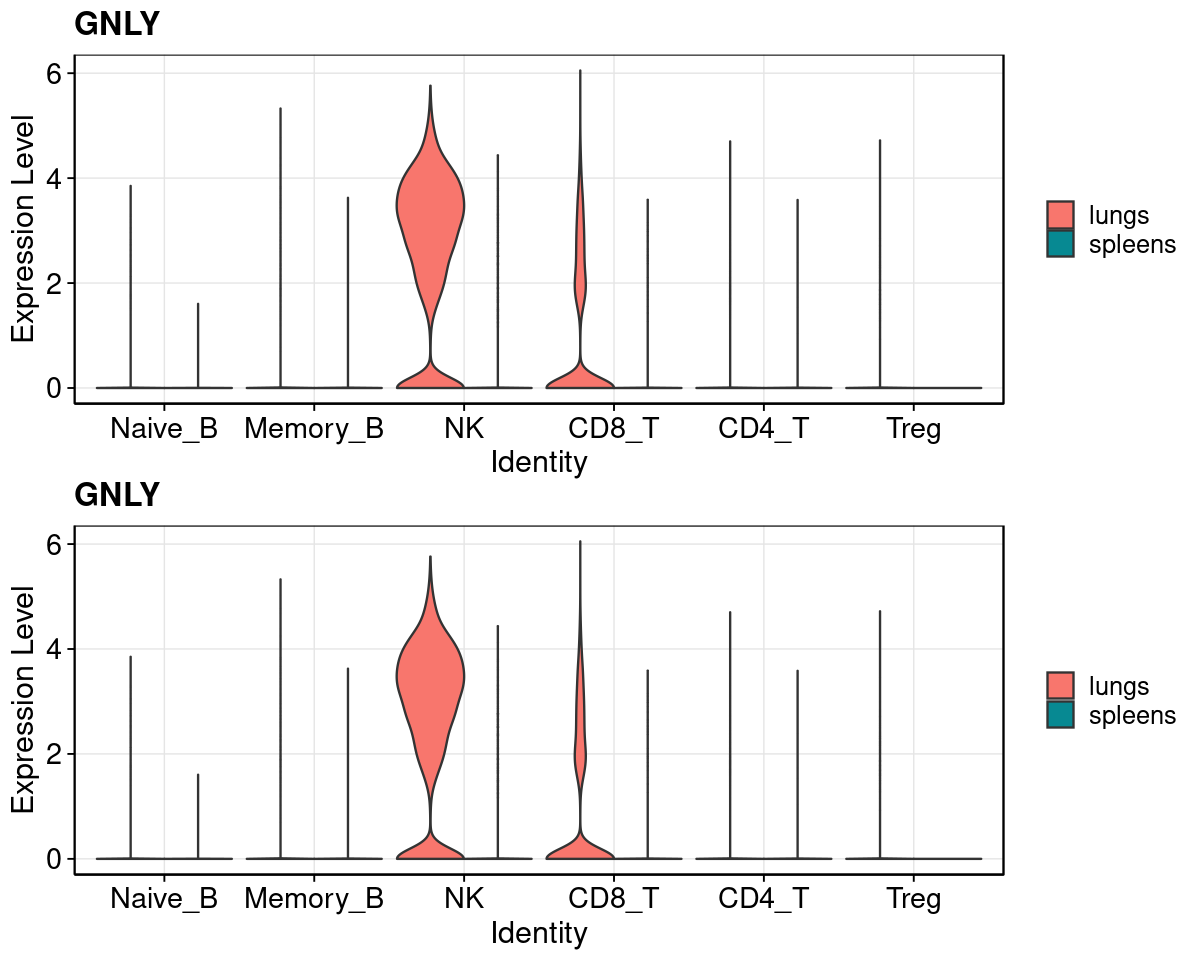

In [15]:
options(repr.plot.width=10, repr.plot.height=8)
p1 + p1

<a id='section5'></a>

## Examine the functions of lung or spleen DE genes 

We performed GO enrichment test for DE genes one cell type at at time separately for each tissue.

In [ ]:
## Prepare inputs for GO enrichment
bkgGenes <- unique(tests$Other$gene)
lung_up <- gginput[gginput$group == "Lung Up-regulated", ]
genesets <- lapply(split(lung_up, lung_up$cluster), function(i) {i$gene})
spleen_up <- gginput[gginput$group == "Spleen Up-regulated", ]
genesets <- lapply(split(spleen_up, spleen_up$cluster), function(i) {i$gene})

In [ ]:
## Bash 
Rscript --vanilla code/run_GO_enrichment.R --geneset lung_up.RDS --bkg genesets.RDS --out lung_upreg
Rscript --vanilla code/run_GO_enrichment.R --geneset spleen_up.RDS --bkg genesets.RDS --out spleen_upreg

In [ ]:
## Visulize GO enrichment outputs
go_list <- readRDS("lung_upreg_GO_enrichment.RDS")
feature = "Biological"
go_tbl <-
  do.call(rbind, go_list) %>%
    filter(k %in% ct_order[1:5])
write.table(go_tbl %>% filter(FDR <= 0.05 & grepl("Biological", database)) %>% dplyr::select(-database), "tables/Enriched_GO_BP_lungUp.txt", quote = F, sep = "\t")
toshow <- 
    unique(
      go_tbl %>% 
        filter(FDR <= 0.05 & grepl(feature, database)) %>%
            group_by(k) %>%
            slice_max(n = 7, order_by = enrichmentRatio) %>%
            pull(description))
p2 <-
ggplot(
    go_tbl %>% 
      filter(grepl(feature, database) & description %in% toshow & 
               FDR <= 0.05) %>%
      mutate(FDR = ifelse(FDR == 0, 10^(-10), FDR),
             Enrichment = enrichmentRatio),
    aes(y = description,
        x = factor(k, levels = ct_order[1:5]),
        size = Enrichment,
        color = -log10(FDR))) + 
    geom_point() + xlab("") + ylab("") + 
     # scale_fill_gradient(
     #   limits = c(0, 4),
     #   oob = squish) +
    theme_pub() + #ggtitle("GO BP enrichment for lung up-regulated genes") 
    theme(axis.text.x = element_text(angle = 45, vjust = 0.5),
          axis.text.y = element_text(),
          legend.position = "bottom")
p2

In [ ]:
go_list <- readRDS("spleen_upreg_GO_enrichment.RDS")
feature = "Biological"
go_tbl <-
  do.call(rbind, go_list) %>%
    filter(k %in% ct_order[1:5])
write.table(go_tbl %>% filter(FDR <= 0.1 & grepl("Biological", database)) %>% dplyr::select(-database), "tables/Enriched_GO_BP_spleenUp.txt", quote = F, sep = "\t")

toshow <- 
    go_tbl %>% 
      filter(FDR <= 0.1 & grepl(feature, database)) %>%
          group_by(k) %>%
          pull(description)

ggplot(
    go_tbl %>% 
      filter(grepl(feature, database) & description %in% toshow),
    aes(y = description,
        x = factor(k, levels = ct_order[1:5]),
        size = enrichmentRatio,
        color = -log10(FDR_adj))) + 
    geom_point() + xlab("") + ylab("") + 
    theme_pub() + ggtitle("GO BP enrichment for spleen up-regulated genes") 